# Multi-Agent Cleaning Robots: Coordination Graph with Max-Plus Message Passing

**Multi-Agent Systems (TEC), Activity 2** · 2026-11-24

**Group members**

| Name | ID |
|---|---|
| Alan Oropeza Saucedo | A01661614 |
| Armando Vásquez Ambrocio | A01669283 |
| David Alejandro Goncalves Pestana | A01669122 |
| Hugo Fernando Rodríguez Montiel | A01782589 |
| Lorenz Rasbach | A01832437 |

**Contents.** 1. Introduction · 2. Methodology · 3. Implementation · 4. Results · 5. Analysis · 6. Conclusion · 7. GitHub link · 8. References

## 1. Introduction

### 1.1 Problem

A team of autonomous cleaning robots operates in a room of $20 \times 30$ cells (600 cells). At the beginning of each simulation a number of cells are chosen at random to be dirty (uniformly, without overlap), and $N$ robots are placed on random clean cells. The goal is to clean **all** dirty cells in at most **500 time steps**. At every step a robot that stands on a dirty cell cleans it; otherwise it moves to one of its 8 neighbors or stays.

For every simulation we measure (1) the time needed until all cells are clean (or the maximum time), (2) the percentage of clean cells at the end, and (3) the number of movements made by all robots. The main output is the **success probability**: the fraction of 100 simulations in which every dirty cell is cleaned within 500 steps.

### 1.2 Motivation

In Activity 1 (M1) the robots were purely reactive: they clean when their cell is dirty and otherwise walk randomly. They ignore each other, so they revisit clean cells, bump into walls and block one another, and the cost of adding robots grows quickly. Coordination should let robots head for different dirty cells, so that the same work is shared with less wasted movement.

### 1.3 Coordination methods

The assignment offers two mechanisms, of which **one** has to be chosen:

- **Option A: coordination graph + Max-Plus message passing**: Robots that are close to each other are connected in a graph, each robot has a local utility, each edge a pairwise payoff, and Max-Plus finds the best joint action.
- **Option B: artificial potential fields**, where robots are pulled toward the nearest dirty cell and pushed away from each other.

We implemented **Option A**. The reactive random robots of M1 are kept only as the **baseline** to compare with.

## 2. Methodology

### 2.1 Grid setup and assumptions

| Item | Value |
|---|---|
| Room | $20 \times 30$ cells, 8-cell (Moore) neighborhood, walls at the border |
| Dirty cells | 100 and 200, uniformly at random, no overlap |
| Robots | $N \in \{1, 2, 3, 4, 5, 8, 16\}$, each on a random clean cell, no two on the same cell |
| Time limit | 500 steps |
| Simulations | 100 per configuration (seeds 0 to 99) |
| Methods | Max-Plus (Option A) and random reactive robots (baseline) |

Assumptions and conventions:

- **Random seed.** A seed fixes the dirt layout. The same 100 seeds are used for every robot count and for both methods, so the comparison between methods is paired and the whole experiment is reproducible.
- **Boundary behavior.** A move outside the room is impossible: the robot stays where it is (*wall bump*). In Max-Plus such moves get a utility of $-10^9$, so they are never planned.
- **Occupied cells.** A robot cannot move into a cell that is occupied by another robot (*blocked move*).
- **Cleaning.** A robot standing on a dirty cell cleans it during its step instead of moving. Because robots start on clean cells, the first step is always a move.
- **Activation.** Within a step the robots act one after the other in random order.
- **Time.** The time is the step at which the last dirty cell is cleaned. If the room is not clean after 500 steps, the run is a failure and its time is counted as 500.
- **Clean percentage.** It is measured over all 600 cells, so it already starts at 83.3% (100 dirty cells) or 66.7% (200 dirty cells).
- **Centralized computation.** The message passing between robots is simulated centrally inside the model at every step.

### 2.2 Payoffs

Every robot has 9 actions: stay, or move to one of the 8 neighbors. Max-Plus maximizes the global payoff

$$G(a) = \sum_i q_i(a_i) + \sum_{(i,j) \in E} f_{ij}(a_i, a_j)$$

where $E$ contains an edge between two robots whenever their **Manhattan distance is at most $d = 4$**.

**Local utility $q_i(a_i)$**

| Symbol | Action of robot $i$ | Value |
|---|---|---|
| $a$ | move to a **dirty** cell | 10 |
| $b$ | **stay** | −1 |
| $c$ | move to a **clean** cell | 0, plus 2 per unit of distance gained toward the nearest dirty cell (*shaping*) |
| – | move outside the room | $-10^9$ |

A robot that stands on a dirty cell will clean it, so for it only "stay" is allowed.

**Pairwise payoff $f_{ij}(a_i, a_j)$**

| Symbol | Situation | Value |
|---|---|---|
| $u$ | the two robots go to **different** cells (coverage) | 0.5, plus 0.5 per unit by which the two target cells are farther apart than the robots are now (*spread*) |
| $v$ | both **move** to the **same** cell (congestion) | −20 |
| $w$ | otherwise (one robot moves into the cell where the other stays) | −20 |

Two parts go **beyond the assignment** and are our own design choices: the *shaping* bonus in $c$ and the *spread* bonus in $u$. Without a pull toward dirt, a robot would see all clean cells as equal (value $c$) and wander, so the shaping term gives it a direction. 

### 2.3 Algorithm

At every step the model builds the coordination graph, computes $q_i$ and $f_{ij}$, runs Max-Plus, and then the robots act:

1. **Graph.** Connect robots $i$ and $j$ if their Manhattan distance is $\le d$.
2. **Utilities.** Compute $q_i(a_i)$ for each robot and $f_{ij}(a_i, a_j)$ for each edge.
3. **Messages.** Every robot $i$ sends each neighbor $j$ a message

$$\mu_{ij}(a_j) = \max_{a_i}\Big[\, q_i(a_i) + f_{ij}(a_i, a_j) + \sum_{k \in N(i) \setminus j} \mu_{ki}(a_i) \Big]$$

   The message is normalized (its maximum is subtracted) and damped with the old one: $\mu \leftarrow 0.5\,\mu_{old} + 0.5\,\mu_{new}$. All messages are updated synchronously, for at most 30 iterations or until they change by less than $10^{-6}$.
4. **Decision.** Every robot picks $a_i^* = \arg\max_{a_i}\big[q_i(a_i) + \sum_k \mu_{ki}(a_i)\big]$. Because the graph can contain cycles, where Max-Plus is not guaranteed to converge, we use the *anytime* variant: the best joint action found in any iteration (including the one before any message) is kept.
5. **Execution.** Robots act in random order. A robot whose target cell is still occupied waits until the occupant has moved away. Without this, a robot following a teammate would be blocked only because it acted first. Robots that still cannot move act at the end and are blocked.

### 2.4 Pseudocode and flowchart

```text
for step t = 1 .. 500:
    edges <- {(i, j) : manhattan(pos_i, pos_j) <= d}
    for each robot i:           q_i(a)       <- local utility of each of the 9 actions
    for each edge (i, j):       f_ij(ai, aj) <- pairwise payoff
    mu_ij <- 0 for every directed edge
    best  <- argmax_a q_i(a) for each robot              # before any message
    for iteration = 1 .. 30:
        for each directed edge (i -> j):
            m     <- max over ai of [ q_i + f_ij + sum_{k != j} mu_ki ]
            mu_ij <- 0.5 * mu_ij + 0.5 * normalize(m)
        candidate <- argmax_a [ q_i + sum_k mu_ki ] for each robot
        if G(candidate) > G(best): best <- candidate      # anytime variant
        if messages changed by less than 1e-6: stop iterating
    plannedAction_i <- best_i
    for each robot i in random order (wait while its target cell is occupied):
        if the cell of i is dirty: clean it
        else: move to the planned cell (stay if outside the room or occupied)
    record metrics (clean %, moves, blocked moves, wall bumps)
    if no dirty cell is left: stop
```

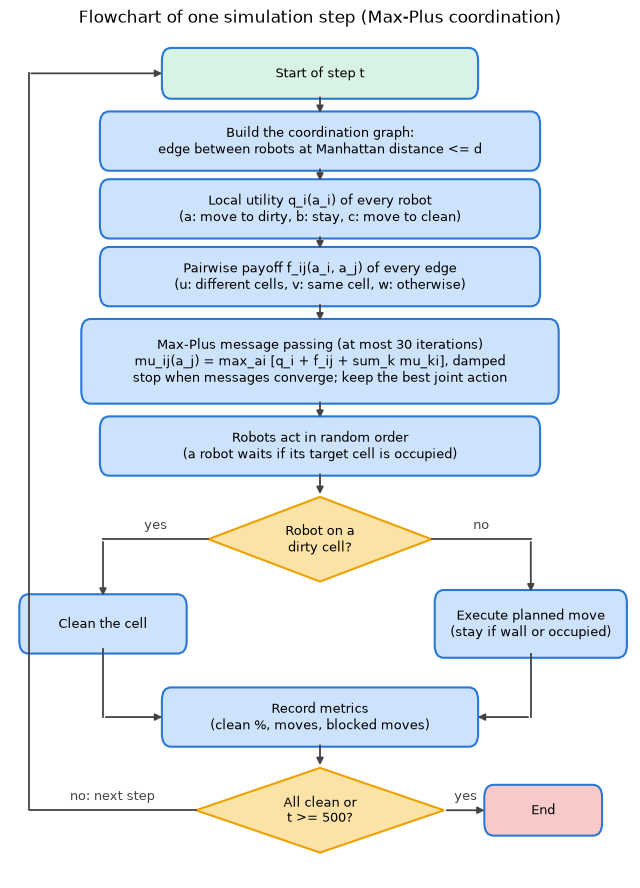

In [1]:
import sys
import pandas as pd
from IPython.display import display

sys.path.insert(0, "experiments")
from activity2 import (
    AGENT_COUNTS,
    DIRTY_COUNTS,
    buildActivity2Summary,
    buildActivity2Table,
    plotSnapshot,
    plotSuccessHistogram,
    plotTimeVsAgents,
    runActivity2Sweep,
    saveActivity2Results,
)
from report_figures import (
    buildSpeedupTable,
    plotFailedMoves,
    plotFlowchart,
    plotMovesVsAgents,
    plotSpeedupEfficiency,
)
from run_experiments import resultsDir

plotFlowchart(showPlot=True)

## 3. Implementation

### 3.1 Mesa model structure

The simulation is written in Python with Mesa.

| File | Key elements |
|---|---|
| `cleaning_model/agents.py` | `CleaningAgent(CellAgent)`: `step()` cleans a dirty cell, otherwise moves (`plannedAction` from Max-Plus, or a random neighbor in `reactive` mode). Counters: `moves`, `wallBumps`, `blockedMoves`, `cellsCleaned`. |
| `cleaning_model/model.py` | `CleaningModel(mesa.Model)`: an `OrthogonalMooreGrid` with a boolean `dirty` property layer, random clean start cells, a `DataCollector`, and `step()` / `planJointAction()` / `executeJointAction()`. The parameter `coordination` selects `"maxplus"` or `"reactive"`. |
| `cleaning_model/coordination.py` | Payoff values (`DEFAULT_PAYOFFS`), `buildEdges` (graph), `localUtilities` ($q_i$), `pairwisePayoff` ($f_{ij}$). |
| `cleaning_model/maxplus.py` | `maxPlus` (message passing, damping, anytime variant) and `globalPayoff` ($G$). |
| `experiments/activity2.py` | The sweep with `mesa.batch_run`, the results table, the success histogram, the time plot and the snapshot. |
| `experiments/report_figures.py` | The flowchart, speedup, moves and failed-move figures of this report. |

Metrics are collected with Mesa's `DataCollector` (clean percentage, dirty cells, total moves, wall bumps, blocked moves, time at which the room became clean).

### 3.2 How coordination is computed

In `CleaningModel.step()` with `coordination="maxplus"`:

1. `planJointAction()` builds the edges with `buildEdges`, the utilities with `localUtilities` and `pairwisePayoff`, calls `maxPlus`, and stores the chosen action in each agent's `plannedAction`.
2. `executeJointAction()` lets the agents call `step()` in random order, delaying agents whose target is occupied.
3. The model updates the time at which the room became clean, the running state and the data collector.

With `coordination="reactive"` the model just calls `agents.shuffle_do("step")` and every agent moves randomly, as in M1.

## 4. Results

The next cell runs the whole experiment: 2 methods × 2 dirt levels × 7 robot counts × 100 seeds = 2,800 simulations (about two minutes). Set `RUN_SWEEP = False` to reload the saved results instead.

In [2]:
RUN_SWEEP = True

if RUN_SWEEP:
    df = runActivity2Sweep()
    summaryDf = buildActivity2Summary(df)
    saveActivity2Results(df, summaryDf)
else:
    df = pd.read_csv(resultsDir / "activity2_sweep.csv")
    summaryDf = pd.read_csv(resultsDir / "activity2_summary.csv")

print(f"{len(df)} simulations")

  0%|          | 0/700 [00:00<?, ?it/s]

  0%|          | 0/700 [00:00<?, ?it/s]

  0%|          | 0/700 [00:00<?, ?it/s]

  0%|          | 0/700 [00:00<?, ?it/s]

2800 simulations


### 4.1 Success probability

Fraction of the 100 simulations in which **all** dirty cells are cleaned within 500 steps, for the Max-Plus robots and the random robots of M1.

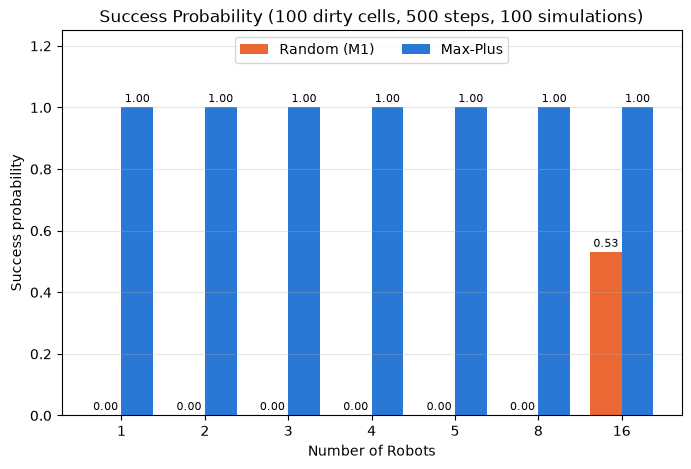

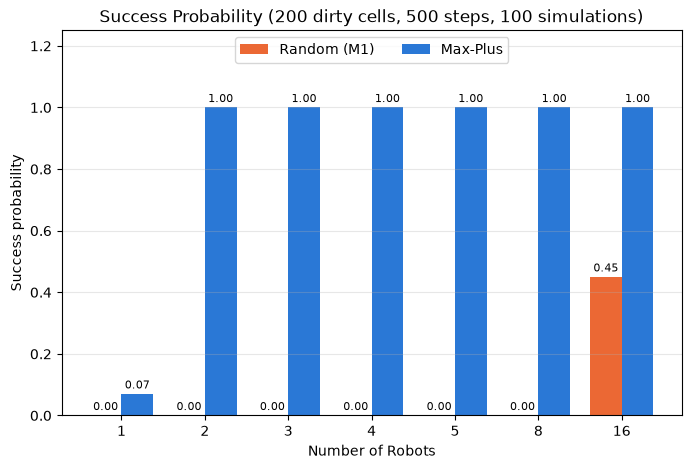

In [3]:
for dirtyCount in DIRTY_COUNTS:
    plotSuccessHistogram(summaryDf, dirtyCount, showPlot=True)

### 4.2 Results table

Mean ± standard deviation over the 100 simulations. *Steps* is the time until all cells are clean (500 for a failed run, so a mean of 500.0 means that no run finished). *Clean %* is the percentage of clean cells over the whole room at the end. *Moves* is the total number of movements of all robots.

In [4]:
table = buildActivity2Table(summaryDf)
display(table[table["Dirty"] == 100].reset_index(drop=True))

,Dirty,Method,Robots,Success,Steps,Clean %,Moves
0,100,Max-Plus,1,1.00,312.0 ± 11.6,100.0 ± 0.0,212 ± 12
1,100,Max-Plus,2,1.00,169.5 ± 12.9,100.0 ± 0.0,239 ± 26
2,100,Max-Plus,3,1.00,119.5 ± 11.2,100.0 ± 0.0,258 ± 33
3,100,Max-Plus,4,1.00,95.8 ± 11.6,100.0 ± 0.0,283 ± 46
4,100,Max-Plus,5,1.00,80.6 ± 10.9,100.0 ± 0.0,302 ± 54
5,100,Max-Plus,8,1.00,53.6 ± 6.6,100.0 ± 0.0,328 ± 52
6,100,Max-Plus,16,1.00,30.4 ± 3.9,100.0 ± 0.0,384 ± 61
7,100,Random (M1),1,0.00,500.0 ± 0.0,88.3 ± 1.1,443 ± 12
8,100,Random (M1),2,0.00,500.0 ± 0.0,91.8 ± 1.3,891 ± 21
9,100,Random (M1),3,0.00,500.0 ± 0.0,94.1 ± 1.3,1344 ± 26


In [5]:
display(table[table["Dirty"] == 200].reset_index(drop=True))

,Dirty,Method,Robots,Success,Steps,Clean %,Moves
0,200,Max-Plus,1,0.07,499.7 ± 1.2,99.4 ± 0.4,303 ± 3
1,200,Max-Plus,2,1.00,273.2 ± 14.2,100.0 ± 0.0,346 ± 28
2,200,Max-Plus,3,1.00,188.6 ± 10.2,100.0 ± 0.0,366 ± 30
3,200,Max-Plus,4,1.00,146.7 ± 11.9,100.0 ± 0.0,386 ± 47
4,200,Max-Plus,5,1.00,119.5 ± 8.6,100.0 ± 0.0,397 ± 43
5,200,Max-Plus,8,1.00,81.1 ± 7.8,100.0 ± 0.0,447 ± 61
6,200,Max-Plus,16,1.00,46.0 ± 5.0,100.0 ± 0.0,531 ± 77
7,200,Random (M1),1,0.00,500.0 ± 0.0,76.2 ± 1.7,417 ± 13
8,200,Random (M1),2,0.00,500.0 ± 0.0,83.2 ± 1.9,848 ± 20
9,200,Random (M1),3,0.00,500.0 ± 0.0,87.6 ± 2.6,1288 ± 26


### 4.3 Time, movements and speedup

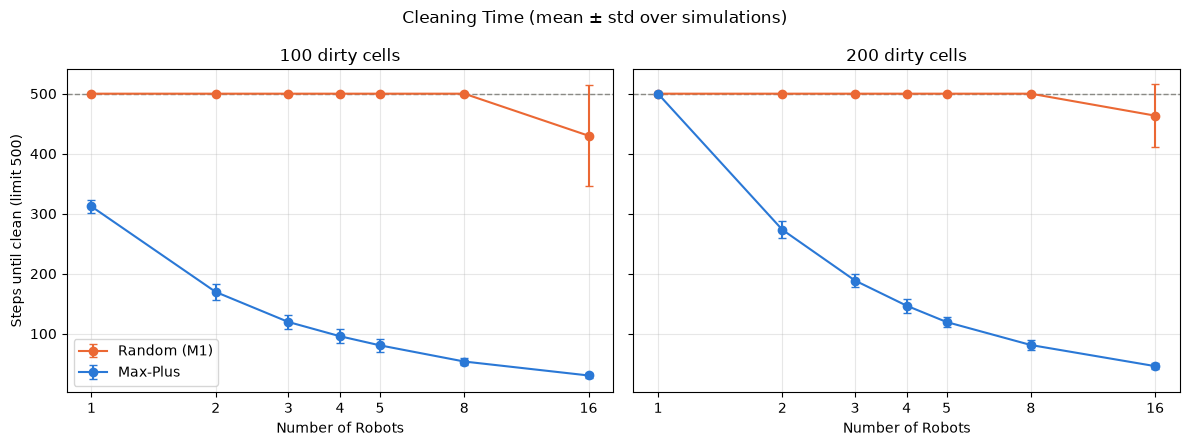

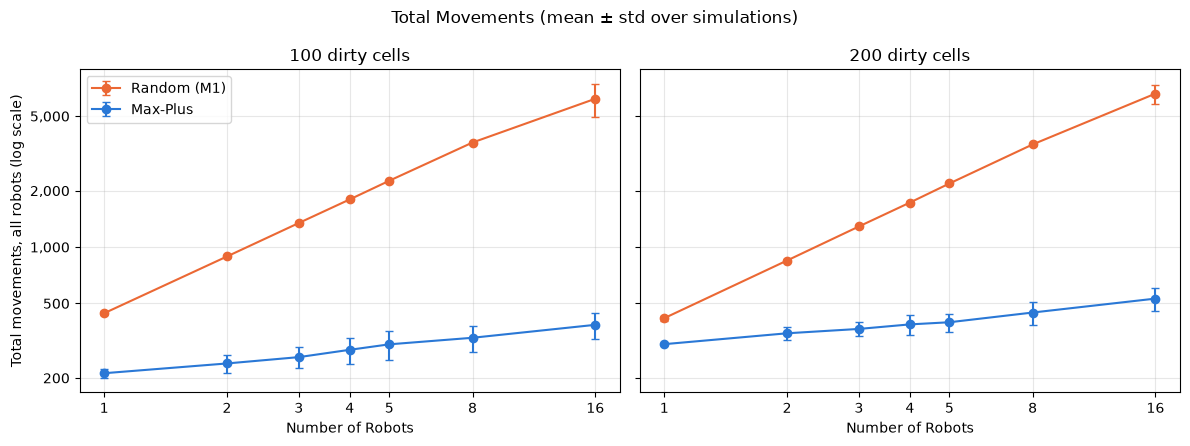

In [6]:
plotTimeVsAgents(summaryDf, showPlot=True)
plotMovesVsAgents(summaryDf, showPlot=True)

**Speedup and efficiency of Max-Plus** (100 dirty cells). *Speedup* is $T(1)/T(k)$, the time with one robot divided by the time with $k$ robots, computed per seed and averaged. *Efficiency* is the speedup divided by $k$, 1 means that every robot is fully useful.

,numAgents,MeanSteps,Speedup,CI95Speedup,Efficiency,CI95Efficiency
0,1,312.02,1.000,0.000,1.000,0.000
1,2,169.54,1.849,0.027,0.925,0.013
2,3,119.53,2.631,0.049,0.877,0.016
3,4,95.78,3.301,0.077,0.825,0.019
4,5,80.60,3.938,0.106,0.788,0.021
5,8,53.65,5.896,0.139,0.737,0.017
6,16,30.41,10.413,0.257,0.651,0.016


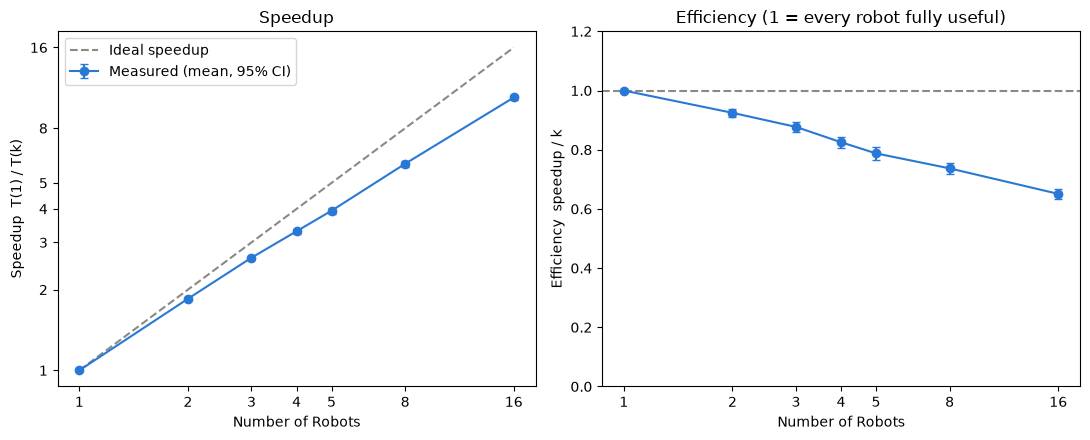

In [7]:
speedupTable = buildSpeedupTable(df, "maxplus", 100)
display(speedupTable.round(3))
plotSpeedupEfficiency(speedupTable, showPlot=True)

### 4.4 Sample simulation

One Max-Plus simulation with 4 robots and 100 dirty cells (seed 0) at steps 0, 25 and 50. Brown cells are dirty, blue dots are robots, and purple lines are the edges of the coordination graph (robots at Manhattan distance $\le 4$).

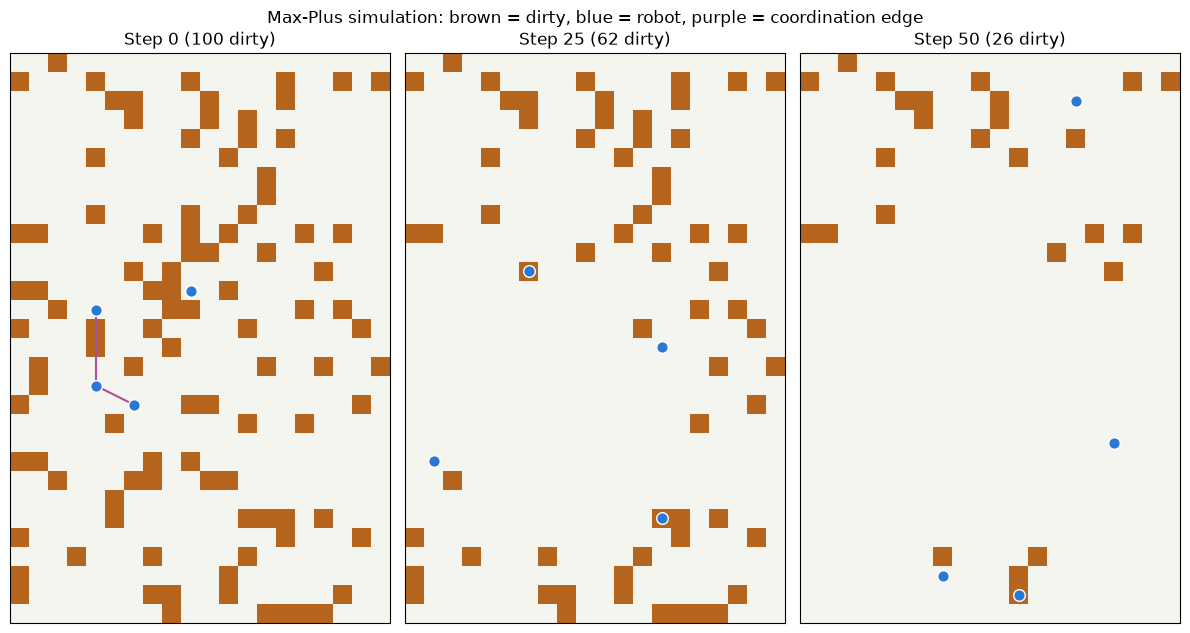

In [8]:
plotSnapshot(showPlot=True)

## 5. Analysis

### 5.1 Which method scales better?

**Max-Plus scales much better than the random robots.**

- **Success.** With 100 dirty cells, Max-Plus succeeds in 100% of the simulations for every robot count from 1 to 16. The random robots never succeed with 1 to 8 robots and reach only 53% with 16 robots. With 200 dirty cells a single Max-Plus robot is not enough (7% success: it needs more than 500 steps), but from 2 robots on every run succeeds, while the random robots again fail for 1 to 8 robots and reach 45% with 16.
- **Time.** The cleaning time of Max-Plus falls steadily: with 100 dirty cells from 312.0 ± 11.6 steps (1 robot) to 30.4 ± 3.9 steps (16 robots); with 200 dirty cells from 273.2 steps (2 robots) to 46.0 steps (16 robots). The random robots always use the whole 500 steps up to 8 robots, so their clean percentage after 500 steps (88% with 1 robot and 99% with 8 robots for 100 dirty cells) is the only thing that differs.
- **Diminishing returns.** The speedup of Max-Plus is close to ideal for a few robots, but the efficiency drops steadily: 0.93 with 2 robots, 0.83 with 4, 0.74 with 8 and 0.65 with 16. Doubling from 8 to 16 robots reduces the time by only 43% (from 53.6 to 30.4 steps).

A likely reason for the drop is that when only few dirty cells are left, they are scattered over the room and only the robots nearby can use them, while the others have to travel. In addition, the graph connects only robots within distance 4, so robots farther apart do not coordinate at all. This explanation was not tested.

### 5.2 Congestion versus coverage

The two terms of the payoff pull in opposite directions. Coverage (*a*, *c* with shaping, *u* with spread) sends every robot toward dirt and away from the others; the congestion terms *v* and *w* ($-20$, larger than the reward $a = 10$) make two robots never want the same cell. The cost is that one robot sometimes yields and loses a step.

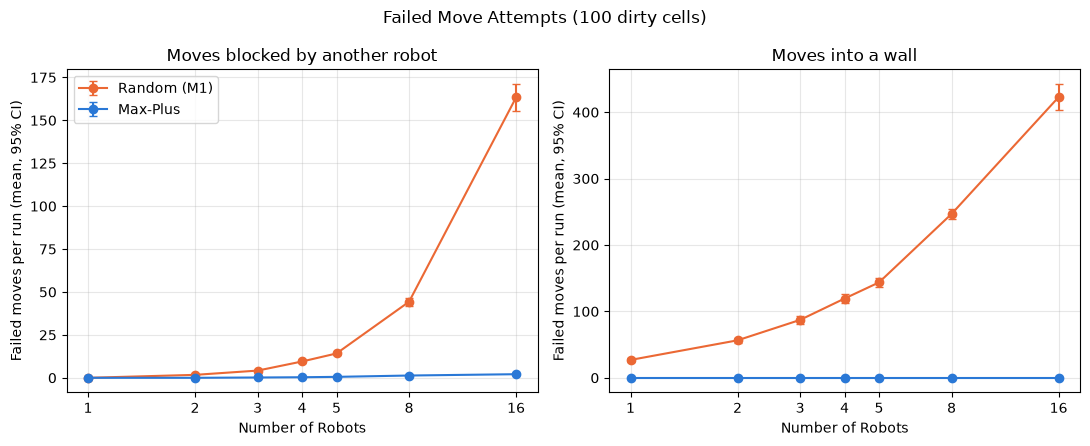

In [9]:
plotFailedMoves(df, 100, showPlot=True)

- **Wasted movement.** Max-Plus makes almost no failed moves: no wall bumps at all (walls are excluded by the utility) and, with 100 dirty cells, at most 2.1 moves blocked by another robot per run (with 16 robots). The random robots bump into walls 26.9 times with 1 robot and 422.7 times with 16 robots, and are blocked by another robot 163.3 times per run with 16 robots.
- **Total movements.** For 100 dirty cells Max-Plus uses 212 movements with 1 robot and 384 with 16 robots (+81%). The random robots use 443 with 1 robot and 6,194 with 16 robots (16 times more). With 200 dirty cells the figures are 346 (2 robots) to 531 (16 robots) for Max-Plus and 417 (1 robot) to 6,598 (16 robots) for the random robots.
- **Trade-off.** More robots reduce the time but increase the total movement (energy): for Max-Plus the movement grows only slowly, while for random robots it grows almost linearly with the number of robots, because every robot keeps walking even when it is useless. So for the random robots speed is bought with a very high cost, while for Max-Plus it is bought cheaply, but with decreasing efficiency.

### 5.3 Limitations

- **Max-Plus is exact only on trees.** On graphs with cycles the messages count the same information more than once, so the beliefs can overestimate the value of a joint action and the algorithm may not converge. With more robots the graph has more cycles.
- **Own payoff design.** The shaping and spread term values (2 and 0.5), the payoffs $a, b, c, u, v, w$ and the graph distance $d = 4$ were chosen by hand. Part of the large advantage over the random robots may come from the shaping term and not from Max-Plus itself.
- **Swaps are not penalized.** Two robots that exchange cells are given the payoff $u$ (different target cells), although the execution step then blocks them.
- **Centralized simulation.** The message passing is computed in one place, with perfect and instantaneous communication. A real team of robots would need a communication protocol.
- **Little resolution in the success probability.** For most configurations it is 0 or 1, so the time, the movements and the efficiency tell more about the scaling than the histogram. One robot cannot clean 200 cells in 500 steps in this room, so that configuration cannot succeed.
- **Baseline.** The random robots now start on random clean cells, so their numbers differ slightly from the M1 report.

## 6. Conclusion

1. **Coordination works.** With a coordination graph and Max-Plus message passing, the robots clean the $20 \times 30$ room in every one of the 100 simulations for 100 dirty cells (1 to 16 robots) and for 200 dirty cells from 2 robots on. The random robots of M1 fail in all simulations up to 8 robots and succeed in only about half of them with 16 robots.
2. **Number of robots and time.** For Max-Plus, the time falls from 312 to 30 steps (100 dirty cells) when going from 1 to 16 robots, a speedup of 10.4 against the ideal 16.
3. **Diminishing returns.** The efficiency falls from 0.93 (2 robots) to 0.74 (8 robots) and 0.65 (16 robots), and going from 8 to 16 robots saves only 43% of the time. For this room, **about 4 to 8 robots are a good compromise**: 4 robots give a speedup of 3.3 and 8 robots a speedup of 5.9 with efficiency of at least 0.74, and the total movement is only 1.3 to 1.6 times that of a single robot.
4. **Speed versus movement.** More robots finish earlier but move more in total (Max-Plus: 212 to 384 movements; random: 443 to 6,194). Max-Plus keeps almost all of these movements useful, with practically no wall bumps or blocked moves.
5. **Suggestions for improvement.** (a) Tune the payoffs and $d$, and run an ablation without the shaping and spread terms to measure the contribution of Max-Plus itself. (b) Penalize robots that swap cells. (c) Compare with the potential-fields option (Option B). (d) Study larger rooms and more dirt, where the point of diminishing returns is expected to move to more robots. (e) Test the effect of limited communication (a smaller $d$ or lost messages).

## 7. GitHub link

[Link to the GitHub repository](https://github.com/lorenz-r/tec-agent-class-MAS_A2)

## 8. References

- Guestrin, C., Lagoudakis, M., and Parr, R. (2002). *Coordinated reinforcement learning.* In Proceedings of the 19th International Conference on Machine Learning (ICML).
- Kok, J. R., and Vlassis, N. (2006). *Collaborative multiagent reinforcement learning by payoff propagation.* Journal of Machine Learning Research, 7, 1789–1828.
- Kazil, J., Masad, D., and Crooks, A. (2020). *Utilizing Python for agent-based modeling: the Mesa framework.* In Social, Cultural, and Behavioral Modeling (SBP-BRiMS 2020), Springer.
- Course assignment: *MAS. Activity_2*, Tecnológico de Monterrey, 2026.